# 17장 실습. 스마트 인그레스 게이트웨이

들어오는 요청 가운데 상당수는 LLM 이 필요 없다. 인사·자주 묻는 질문은 정해진 답으로, 주문 조회 같은 질문은 내부 API 로 끝난다. 게이트웨이는 요청 하나를 읽고 셋 중 어디로 보낼지 정한다. 확신이 모자라면 LLM 으로 보낸다(잘못 로컬에서 처리하는 쪽이 더 비싸기 때문이다).

```
요청 ─▶ 게이트웨이 (complexity: canned | structured | complex, reasoning: noul)
          ├─ canned · 확신 ≥ t      ─▶ FAQ 답
          ├─ structured · 확신 ≥ t  ─▶ 내부 API
          └─ complex · 추론 필요 · 확신 < t ─▶ 상위 LLM
```

| 절 | 내용 |
|---|---|
| 17.1 | 게이트웨이 질문과 판정 (Jev) |
| 17.2 | 라우팅 정책 — 어디로 갔고, 잘못 간 것은 무엇인가 |
| 17.3 | 확신 임계값 — 로컬 처리율과 오라우팅의 맞바꿈 |
| 17.4 | 음성 턴테이킹 |
| 17.5 | 용도별 증류 — 로컬 LLM 으로 요청을 만들고 Jev 로 매겨 Laya 를 학습한다 |
| 17.6 | 엔진 비교 — Jev · Laya 기본 · Laya 증류 · 로컬 LLM |

평가 데이터는 저자가 쓰고 정답을 매긴 요청 48개(`data/recipes/gateway_ko.jsonl`)와 음성 전사 조각 24개(`turn_ko.jsonl`)다. 이 둘은 학습에 쓰지 않는다. 시스템은 Jev 로 먼저 짓는다. 질문과 정책의 문제를 엔진 문제와 섞지 않고 보기 위해서다.

In [1]:
import os, json, time, random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests
import koreanize_matplotlib  # noqa: F401
from dotenv import load_dotenv
from requests.adapters import HTTPAdapter, Retry

load_dotenv()
DATA, OUT = Path("data"), Path("out")
OUT.mkdir(exist_ok=True)
TASKS = ["topic", "entails", "positive", "similarity"]
COLOR = {"topic": "#2a78d6", "entails": "#eb6834", "positive": "#1baf7a", "similarity": "#eda100"}
pd.set_option("display.precision", 3)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
read_jsonl = lambda p: [json.loads(l) for l in Path(p).read_text(encoding="utf-8").splitlines() if l.strip()]

JEV_URL = os.getenv("JEV_URL", "https://api.typesafe.ai")
http = requests.Session()
http.mount(JEV_URL, HTTPAdapter(max_retries=Retry(total=4, backoff_factor=0.5, status_forcelist=[408, 429, 500, 502, 503, 504])))

def ask(state, questions, model="jev-latest"):
    r = http.post(f"{JEV_URL}/v1/systemone", timeout=60, headers={"Authorization": f"Bearer {os.environ['TYPESAFE_API_KEY']}"},
                  json={"model": model, "state": state, "questions": questions})
    r.raise_for_status()
    return r.json() | {"_latency_s": r.elapsed.total_seconds()}

choice = lambda instructions, criteria: {"type": "choice", "instructions": instructions, "criteria": criteria}
score = lambda instructions, levels: {"type": "score", "instructions": instructions, "criteria": levels}
noul = lambda instructions, true="", false="": {"type": "noul", "instructions": instructions} | ({"criteria": {"true": true, "false": false}} if true else {})

def probs_of(answer):
    return answer.get("probabilities") or {"true": answer["noul"], "false": 1 - answer["noul"]}

def judge(item, resp):
    (task, q), = item["questions"].items()
    a = resp["answers"][task]
    pr = {str(k): float(v) for k, v in probs_of(a).items()}
    best = max(pr, key=pr.get)
    pred = {"noul": lambda: pr["true"] >= 0.5, "choice": lambda: best, "score": lambda: int(best)}[q["type"]]()
    return {"id": item["id"], "task": item["task"], "qtype": q["type"], "gold": item["gold"], "model": resp["model"],
            "pred": pred, "probs": pr, "conf": pr[best], "conf_field": a.get("confidence"), "correct": bool(pred == item["gold"]),
            "input_tokens": resp["usage"]["input_tokens"], "latency_s": resp["_latency_s"]}

def run(items, engine=lambda it: ask(it["state"], it["questions"]), workers=4):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(lambda it: judge(it, engine(it)), items))

arrays = lambda recs: (np.array([r["conf"] for r in recs]), np.array([r["correct"] for r in recs], float))

def ece(conf, ok, bins=15):
    idx = np.clip(np.searchsorted(np.linspace(0, 1, bins + 1), conf, side="left") - 1, 0, bins - 1)
    return float(sum(abs(conf[idx == i].mean() - ok[idx == i].mean()) * (idx == i).sum() for i in np.unique(idx)) / len(conf))

import re, hashlib, torch
from laya.train import TrainConfig, finetune

MODELS = Path("models"); MODELS.mkdir(exist_ok=True)
(DATA / "distill").mkdir(exist_ok=True)
write_jsonl = lambda p, rows: Path(p).write_text("".join(json.dumps(r, ensure_ascii=False, default=str) + "\n" for r in rows), encoding="utf-8")
FULL = torch.cuda.is_available()
QKEYS = {"choice": lambda q: list(q["criteria"]), "score": lambda q: [str(i) for i in range(len(q["criteria"]))], "noul": lambda q: ["false", "true"]}
top = lambda a: max(probs_of(a), key=probs_of(a).get)          # 질문 유형과 관계없이 확률이 가장 큰 선택지
conf_of = lambda a: max(probs_of(a).values())
p_true = lambda a: probs_of(a)["true"]

def answer_all(engine, states, questions, workers=1):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(lambda s: engine(s, questions), states))

def teacher_rows(name, states, questions):
    # Jev 가 매긴 확률 분포를 그대로 교사 분포로 쓴다(13장 형식)
    resp = answer_all(ask, states, questions, workers=4)
    dist = lambda q, a: {"probabilities": {k: round(float(probs_of(a)[k]), 6) for k in QKEYS[q["type"]](q)}}
    rows = [{"id": f"{name}-{i:05d}", "state": s, "questions": questions, "gold": {n: dist(q, r["answers"][n]) for n, q in questions.items()}}
            for i, (s, r) in enumerate(zip(states, resp))]
    return rows, sum(r["usage"]["input_tokens"] for r in resp)

def distill(name, rows):
    # 학습 파일을 쓰고 multilingual 에서 파인튜닝한다. GPU 가 없으면 200행·1 epoch 의 빠른 모드로 돈다
    path = DATA / "distill" / f"{name}.jsonl"
    write_jsonl(path, random.Random(0).sample(rows, len(rows))[: [200, None][FULL]])
    t0 = time.perf_counter()
    rep = finetune(str(path), "multilingual", str(MODELS / name), TrainConfig(loss="rlcd", epochs=[1, 4][FULL], seed=0))
    return {"학습 항목(질문 단위)": rep["train_items"], "보정 항목": rep["calibration_items"], "epoch 손실": [round(x, 4) for x in rep["epoch_loss"]],
            "시간(초)": round(time.perf_counter() - t0, 1), "데이터 sha256": hashlib.sha256(path.read_bytes()).hexdigest()[:16]}
print("장치:", torch.cuda.get_device_name(0) if FULL else "CPU", "| 모드:", ["빠른 모드", "전체"][FULL])

gateway, turns = read_jsonl(DATA / "recipes/gateway_ko.jsonl"), read_jsonl(DATA / "recipes/turn_ko.jsonl")
print("요청", len(gateway), "| 전사 조각", len(turns))

장치: NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition | 모드: 전체
요청 48 | 전사 조각 24


## 17.1 게이트웨이 질문 설계

질문은 둘이다. 요청이 어떤 종류인지(choice 3지선다)와 상위 모델의 추론이 필요한지(noul).

In [2]:
GQ = {"complexity": choice("이 요청을 처리하는 데 필요한 것", {
          "canned": "인사, 자주 묻는 질문, 고정된 안내처럼 정해진 답으로 끝난다",
          "structured": "계정·주문·청구 같은 내부 데이터를 조회하면 답이 나온다",
          "complex": "글을 새로 쓰거나, 분석·비교·코드·여러 단계 추론이 필요하다"}),
      "reasoning": noul("이 요청은 여러 단계의 추론이나 계산, 판단 근거 설명이 필요하다",
                        true="비교·예측·원인 분석·계산·검토처럼 생각을 거쳐야 한다",
                        false="찾아서 알려 주거나 정해진 절차를 안내하면 된다")}

def gateway_frame(rs):
    return pd.DataFrame([{"요청": g["text"], "정답": g["complexity"], "판정": top(r["answers"]["complexity"]), "확신": conf_of(r["answers"]["complexity"]),
                          "reasoning": p_true(r["answers"]["reasoning"]), "정답 reasoning": g["reasoning"], "지연(ms)": 1000 * r["_latency_s"]}
                         for g, r in zip(gateway, rs)])

jev_gw = answer_all(ask, [g["text"] for g in gateway], GQ, workers=4)
G = gateway_frame(jev_gw)
print("complexity 정확도:", (G["판정"] == G["정답"]).mean(), "| reasoning 정확도:", ((G["reasoning"] >= 0.5) == G["정답 reasoning"]).mean())
pd.crosstab(G["정답"], G["판정"], margins=True)

complexity 정확도: 0.9583333333333334 | reasoning 정확도: 0.9375


판정,canned,complex,structured,All
정답,,,,
canned,16,0,0,16
complex,0,14,2,16
structured,0,0,16,16
All,16,14,18,48


## 17.2 라우팅 정책과 오라우팅

정책은 코드에 둔다. 확신이 임계값 t 아래거나, complex 거나, 추론이 필요하면 LLM 으로 보낸다. 나머지는 판정대로 FAQ 또는 내부 API 다.

오라우팅은 두 종류다. **위험한 쪽**은 complex 요청이 로컬로 가는 것(엉뚱한 고정 답이 나간다), **비싼 쪽**은 canned·structured 요청이 LLM 으로 가는 것(GPU 시간만 더 든다).

In [3]:
GOLD_ROUTE = {"canned": "FAQ", "structured": "내부 API", "complex": "LLM"}

def route(complexity, conf, reasoning, t=0.85):
    upstream = conf < t or complexity == "complex" or reasoning >= 0.5
    return ["LLM", GOLD_ROUTE[complexity]][not upstream]

def route_summary(G, t=0.85):
    paths = pd.Series([route(c, p, r, t) for c, p, r in zip(G["판정"], G["확신"], G["reasoning"])])
    return {"로컬 처리율": (paths != "LLM").mean(), "경로 정확도": (paths == G["정답"].map(GOLD_ROUTE)).mean(),
            "위험: complex → 로컬": int(((G["정답"] == "complex") & (paths != "LLM")).sum()),
            "비용: 로컬 가능 → LLM": int(((G["정답"] != "complex") & (paths == "LLM")).sum())}, paths

summary, G["경로"] = route_summary(G)
print(summary)
G[G["경로"] != G["정답"].map(GOLD_ROUTE)][["요청", "정답", "판정", "확신", "reasoning", "경로"]]

{'로컬 처리율': np.float64(0.5), '경로 정확도': np.float64(0.8333333333333334), '위험: complex → 로컬': 0, '비용: 로컬 가능 → LLM': 8}


,요청,정답,판정,확신,reasoning,경로
3,환불 규정 알려 주세요,canned,canned,0.80,0.11,LLM
4,영수증은 어디서 출력하나요?,canned,canned,0.65,0.10,LLM
6,앱 최신 버전이 뭐예요?,canned,canned,0.65,0.11,LLM
7,상담원 연결해 주세요,canned,canned,0.75,0.07,LLM
9,배송은 보통 며칠 걸려요?,canned,canned,0.70,0.13,LLM
12,해외에서도 쓸 수 있나요?,canned,canned,0.74,0.21,LLM
13,무료 체험 기간은 며칠인가요?,canned,canned,0.82,0.08,LLM
27,쿠폰 SPRING10 아직 유효해요?,structured,structured,0.76,0.13,LLM


## 17.3 확신 임계값 스윕

t 를 올리면 확신이 모자란 요청이 더 많이 LLM 으로 간다. 위험한 오라우팅은 줄고 로컬 처리율도 준다. 0.5 에서 0.95 까지 옮기며 잰다.

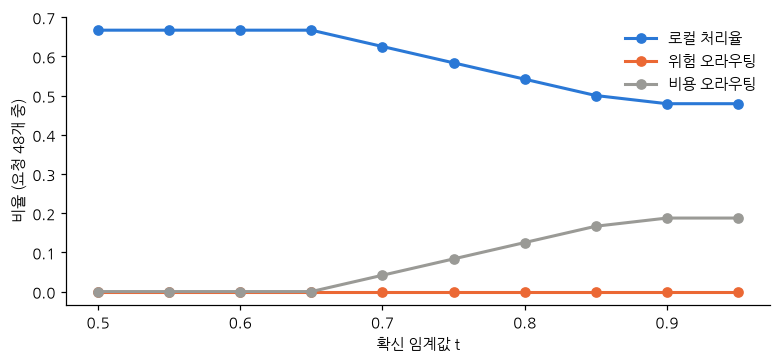

,로컬 처리율,경로 정확도,위험: complex → 로컬,비용: 로컬 가능 → LLM
t,,,,
0.50,0.667,1.000,0,0
0.55,0.667,1.000,0,0
0.60,0.667,1.000,0,0
0.65,0.667,1.000,0,0
0.70,0.625,0.958,0,2
0.75,0.583,0.917,0,4
0.80,0.542,0.875,0,6
0.85,0.500,0.833,0,8
0.90,0.479,0.812,0,9


In [4]:
sweep = pd.DataFrame([{"t": t, **route_summary(G, t)[0]} for t in np.round(np.arange(0.5, 1.0, 0.05), 2)]).set_index("t")
fig, ax = plt.subplots(figsize=(7.2, 3.4), dpi=110)
ax.plot(sweep.index, sweep["로컬 처리율"], marker="o", color="#2a78d6", lw=2, label="로컬 처리율")
ax.plot(sweep.index, sweep["위험: complex → 로컬"] / len(G), marker="o", color="#eb6834", lw=2, label="위험 오라우팅")
ax.plot(sweep.index, sweep["비용: 로컬 가능 → LLM"] / len(G), marker="o", color="#9a9a96", lw=2, label="비용 오라우팅")
ax.set_xlabel("확신 임계값 t"); ax.set_ylabel(f"비율 (요청 {len(G)}개 중)"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(OUT / "nb17_threshold.png", bbox_inches="tight"); plt.show()
sweep

## 17.4 음성 턴테이킹

음성 상담에서는 STT 가 전사한 조각이 계속 들어온다. 매 조각마다 묻는다. 손님 말이 끝났나(답해도 되나), 지금 말이 상담원의 말을 끊으려는 것인가. 이 판단은 사람의 대화 간격(수백 ms) 안에 끝나야 하므로 지연 중앙값을 함께 본다. 네트워크를 건너는 Jev 는 이 조건에서 불리하다. 17.6 에서 로컬 엔진과 견준다.

In [5]:
TQ = {"complete": noul("말하는 사람이 하려던 말을 끝냈다",
                       true="문장이 완결돼 이제 답해도 된다", false="말이 이어질 것 같다(조사·접속사로 끝나거나 숫자를 부르는 중이다)"),
      "interrupt": noul("상대의 말을 끊거나 앞의 말을 정정하려 한다",
                        true="그만, 잠깐, 아니요, 그게 아니라처럼 끼어든다", false="이어서 자기 할 말을 한다")}

def turn_summary(rs):
    ok = lambda q: np.mean([(p_true(r["answers"][q]) >= 0.5) == t[q] for t, r in zip(turns, rs)])
    return {"complete 정확도": ok("complete"), "interrupt 정확도": ok("interrupt"), "턴 지연 중앙값(ms)": 1000 * np.median([r["_latency_s"] for r in rs])}

jev_turn = answer_all(ask, [t["text"] for t in turns], TQ, workers=4)
turn_summary(jev_turn)

{'complete 정확도': np.float64(0.9166666666666666),
 'interrupt 정확도': np.float64(0.9166666666666666),
 '턴 지연 중앙값(ms)': np.float64(175.3925)}

## 17.5 용도별 증류

4부에서 KLUE 로 파인튜닝한 Laya 는 4부 평가셋에서 Jev 에 다가갔지만, 이 장의 질문에는 그 학습이 닿지 않는다. 게이트웨이가 보는 문장은 고객센터 요청이고 질문도 다르기 때문이다. 그래서 이 용도의 학습 데이터를 따로 만든다.

1. 로컬 LLM 이 요청 문장을 만든다. 업종 10개 × 말투 5개 × 종류 3개 = 프롬프트 150개, 프롬프트마다 10줄이다.
2. 턴테이킹 조각은 만든 문장을 단어 경계에서 앞부분만 잘라 만든다. 자른 조각은 「말이 안 끝났다」, 자르지 않은 문장은 「끝났다」가 정답이다. 정답이 자르는 위치로 정해지므로 complete 는 교사가 필요 없다.
3. 같은 모델로 평가 데이터에 대한 로컬 LLM 의 답을 받아 둔다(17.6 의 한 줄). 그런 뒤 모델을 내린다.
4. Jev 가 학습 문장에 확률을 매긴다. 이 분포가 교사다(13장).
5. Laya multilingual 을 이 데이터로 파인튜닝한다(14장의 RLCD).

LLM 이 문장을 만들 때 「canned 요청을 써라」고 시켰더라도 그 의도를 정답으로 쓰지 않는다. 라벨은 Jev 가 매긴다. 의도와 Jev 판정이 얼마나 맞는지는 데이터 점검용으로만 본다.

In [6]:
from transformers import AutoModelForCausalLM, AutoTokenizer

LLM_MODEL = os.environ["LOCAL_LLM_MODEL"]
tok = AutoTokenizer.from_pretrained(LLM_MODEL, padding_side="left")
tok.pad_token = tok.pad_token or tok.eos_token
lm = AutoModelForCausalLM.from_pretrained(LLM_MODEL, dtype="auto", device_map="auto")

def chat_batch(prompts, max_new_tokens=256, batch_size=16, system=None):
    # 프롬프트 여럿을 묶어 generate 한 번에 보낸다(왼쪽 패딩). 서빙 엔진 없이 처리량을 내는 방법이다
    msgs = lambda p: [{"role": "system", "content": system}] * bool(system) + [{"role": "user", "content": p}]
    texts = [tok.apply_chat_template(msgs(p), tokenize=False, add_generation_prompt=True, enable_thinking=False) for p in prompts]
    outs = []
    for i in range(0, len(texts), batch_size):
        enc = tok(texts[i:i + batch_size], return_tensors="pt", padding=True).to(lm.device)
        gen = lm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False)
        outs += tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outs]

chat = lambda prompt, **kw: chat_batch([prompt], **kw)[0]
print(LLM_MODEL, "|", lm.device)

import re

KEYS = {"choice": lambda q: list(q["criteria"]), "score": lambda q: [str(i) for i in range(len(q["criteria"]))], "noul": lambda q: ["true", "false"]}
LINES = {"choice": lambda q: [f"  {k}: {v}" for k, v in q["criteria"].items()],
         "score": lambda q: [f"  {i}: {v}" for i, v in enumerate(q["criteria"])],
         "noul": lambda q: [f"  {k}: {v}" for k, v in (q.get("criteria") or {"true": "그렇다", "false": "아니다"}).items()]}

def gen_prompt(state, q):
    return "\n".join(["[판단할 대상]", json.dumps(state, ensure_ascii=False), "", "[질문]", q["instructions"], "[선택지]", *LINES[q["type"]](q), "",
                       "선택지 키 하나와, 그 답이 맞을 확률을 아래 두 줄 형식으로만 답하라.", "답: <선택지 키>", "확신: <0과 1 사이 숫자>"])

def gen_answer(q, text):
    keys = KEYS[q["type"]](q)
    ans = (re.findall(r"답\s*[:：]\s*(\S+)", text) + [None])[0]
    conf = float((re.findall(r"확신\s*[:：]\s*([01](?:\.\d+)?)", text) + ["nan"])[0])
    p = {k: [(1 - conf) / (len(keys) - 1), conf][k == ans] for k in keys} if ans in keys and conf == conf else {k: 1 / len(keys) for k in keys}
    return {"type": q["type"], "probabilities": p, "noul": p.get("true"), "choice": max(p, key=p.get), "invalid": ans not in keys, "raw": text}

def gen_many(states_questions, batch_size=16):
    # (state, 질문 하나짜리 dict) 목록을 묶어서 생성하고 Jev 모양의 응답으로 바꾼다
    flat = [(s, n, q) for s, qs in states_questions for n, q in qs.items()]
    t0 = time.perf_counter()
    outs = chat_batch([gen_prompt(s, q) for s, _, q in flat], max_new_tokens=24, batch_size=batch_size)
    sec = (time.perf_counter() - t0) / len(flat)
    return [{"model": "llm:" + LLM_MODEL, "answers": {n: gen_answer(q, o)}, "usage": {"input_tokens": 0}, "_latency_s": sec}
            for (s, n, q), o in zip(flat, outs)]

def llm_answers(states, questions, batch_size=16):
    flat, n = gen_many([(s, questions) for s in states], batch_size), len(questions)
    return [{"model": flat[0]["model"], "answers": {k: v for r in flat[i:i + n] for k, v in r["answers"].items()},
             "usage": {"input_tokens": 0}, "_latency_s": sum(r["_latency_s"] for r in flat[i:i + n])} for i in range(0, len(flat), n)]

def lines_of(text):
    # 생성한 목록에서 번호·기호를 떼고 한 줄에 하나씩 꺼낸다
    return [l for l in (re.sub(r"^\s*(\d+[.)]|[-*•])\s*", "", x).strip().strip('"') for x in text.splitlines()) if 4 <= len(l) <= 200]

generate = lambda prompts, max_new_tokens=512: chat_batch(prompts, max_new_tokens=max_new_tokens, batch_size=16)

SECTORS = ["온라인 쇼핑몰", "통신사", "은행 앱", "배달 앱", "업무용 SaaS", "항공사", "보험사", "모바일 게임", "OTT 서비스", "중고 거래 앱"]
STYLES = ["짧은 존댓말", "짧은 반말", "두세 문장의 존댓말", "오타와 줄임말이 섞인 채팅체", "화가 난 말투"]
KIND = {"canned": "인사, 운영 시간·위치·정책처럼 정해진 안내로 끝나는",
        "structured": "주문·결제·계정처럼 고객 본인의 데이터를 조회해야 답할 수 있는",
        "complex": "글을 새로 쓰거나 비교·분석·추천·여러 단계 판단이 필요한"}
plan = [(k, f"{s} 고객센터 채팅창에 들어올 법한, {d} 요청 10개를 {st}로 써라. 한 줄에 하나씩, 번호 없이 요청 문장만 쓴다.")
        for k, d in KIND.items() for s in SECTORS for st in STYLES]
t0 = time.perf_counter()
made = [(k, line) for (k, _), text in zip(plan, generate([p for _, p in plan])) for line in lines_of(text)]
requests_ = list(dict.fromkeys(line for _, line in made))                 # 같은 문장은 한 번만
intent = {line: k for k, line in made}
print(f"요청 {len(requests_)}개 ({time.perf_counter() - t0:.0f}초)")
pd.DataFrame([{"의도": k, "문장": l} for k, l in made]).groupby("의도").head(3)

/home/josh/anaconda3/envs/pytorch/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Ignoring corrupted tree cache file /data/shared/hf/hub/models--Qwen--Qwen3.5-4B/trees/851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a.json: [Errno 13] Permission denied: '/data/shared/hf/hub/models--Qwen--Qwen3.5-4B/trees/851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a.json'
Loading weights: 100%|██████████| 426/426 [00:01<00:00, 308.82it/s]


Qwen/Qwen3.5-4B | cuda:0


[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.
[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


요청 1330개 (130초)


,의도,문장
0,canned,"안녕하세요, 오늘 어떤 도움이 필요하신가요?"
1,canned,고객센터 운영 시간은 평일 오전 9 시부터 오후 6 시까지입니다.
2,canned,"현재 상담원이 대기 중이 아니니, 다음 업무 시간까지 기다려주세요."
523,structured,주문 내역을 조회해 주실 수 있나요?
524,structured,결제 내역을 확인해 주실 수 있나요?
525,structured,회원 정보를 수정해 주실 수 있나요?
1019,complex,"최근 출시된 A, B, C 세 모델의 배터리 수명과 가격 대비 성능을 비교해 주세요."
1020,complex,내 피부 타입에 맞는 가장 적합한 스킨케어 제품 조합을 추천해 주실 수 있나요?
1021,complex,이번 시즌 인기 있는 의류 브랜드 중 내 키와 체형에 맞는 사이즈를 알려주세요.


끼어드는 말은 고객 요청에 거의 없으므로 따로 만든다. 그다음 요청과 끼어드는 말을 전사처럼 바꾼다(문장부호를 뺀다). 문장마다 통째 하나와, 단어 경계에서 자른 앞부분 하나를 만든다.

In [7]:
interrupts = list(dict.fromkeys(l for text in generate([f"{s} 음성 상담 중에 고객이 상담원의 말을 끊거나 앞의 말을 고치며 하는 짧은 말 10개를 써라. 한 줄에 하나씩, 번호 없이."
                                                        for s in SECTORS]) for l in lines_of(text)))
spoken = lambda s: re.sub(r"[.,!?~…]", "", s).strip()
rng = random.Random(2026)

def cut(s):
    words = spoken(s).split()
    return [(" ".join(words), True)] + [(" ".join(words[:rng.randint(1, len(words) - 1)]), False)] * (len(words) > 1)

pieces = [p for s in rng.sample(requests_, min(400, len(requests_))) + interrupts for p in cut(s)]
print("끼어드는 말", len(interrupts), "| 턴 조각", len(pieces))
pd.DataFrame(pieces[:6], columns=["조각", "complete 정답"])

끼어드는 말 39 | 턴 조각 878


,조각,complete 정답
0,승객 수하물 무게 제한은 얼마인가요,True
1,승객 수하물 무게,False
2,계정 연결된 서비스 목록을 조회하고 연결을 해제해 주실 수 있을까요,True
3,계정 연결된 서비스 목록을 조회하고 연결을,False
4,메뉴에 '저칼로리'라고 적혀있는데 칼로리 표가 없네,True
5,메뉴에 '저칼로리'라고 적혀있는데 칼로리 표가,False


모델을 내리기 전에 평가 데이터에 대한 로컬 LLM 의 답을 받아 둔다. 답과 스스로 적은 확신을 글로 받는 방식이다(1·12장의 생성형 엔진). 지연은 질문 둘을 합한 값이다.

In [8]:
llm_gw = llm_answers([g["text"] for g in gateway], GQ)
llm_turn = llm_answers([t["text"] for t in turns], TQ)
del lm; torch.cuda.empty_cache()

Jev 교사로 학습 행을 만든다. 턴 조각은 interrupt 만 Jev 가 매기고, complete 는 자른 위치로 정한 분포(0.95 / 0.05)를 넣는다.

In [9]:
gw_rows, gw_tokens = teacher_rows("gateway", requests_, GQ)
turn_rows, turn_tokens = teacher_rows("turn", [p for p, _ in pieces], {"interrupt": TQ["interrupt"]})
for r, (_, done) in zip(turn_rows, pieces):
    r["questions"], r["gold"]["complete"] = TQ, {"probabilities": {"false": [0.95, 0.05][done], "true": [0.05, 0.95][done]}}

agree = np.mean([max(g := r["gold"]["complexity"]["probabilities"], key=g.get) == intent[r["state"]] for r in gw_rows])
print(f"학습 행 {len(gw_rows) + len(turn_rows)} | LLM 의도와 Jev 판정 일치 {agree:.3f} | Jev 비용 {(gw_tokens + turn_tokens) * 0.042 / 1e6:.4f}달러")
pd.Series(distill("gateway-distill", gw_rows + turn_rows))

학습 행 2208 | LLM 의도와 Jev 판정 일치 0.748 | Jev 비용 0.0408달러


Fetching 5 files: 100%|██████████| 5/5 [00:00<00:00, 2134.51it/s]


train items 4016, calibration items 400, eval items 400 (calibration_slice), skipped {}, device cuda:0
optimizer budget: 4016 train item(s), effective batch up to 64 (micro_batch 8 x grad_accum 8), 252 optimizer updates over 4 epoch(s)


/home/josh/anaconda3/envs/pytorch/lib/python3.11/site-packages/laya/train.py:724: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


epoch 1/4 step 100 loss 0.5551
epoch 1/4 step 200 loss 0.8499
epoch 1/4 step 300 loss 0.4308
epoch 1/4 step 400 loss 0.0355
epoch 1/4 step 500 loss 0.6147
epoch 1/4 mean loss 0.4149
epoch 2/4 step 100 loss 0.3482
epoch 2/4 step 200 loss 0.3655
epoch 2/4 step 300 loss 0.1370
epoch 2/4 step 400 loss 0.7518
epoch 2/4 step 500 loss 0.6021
epoch 2/4 mean loss 0.2607
epoch 3/4 step 100 loss 0.4692
epoch 3/4 step 200 loss 0.0546
epoch 3/4 step 300 loss -0.1098
epoch 3/4 step 400 loss 0.3156
epoch 3/4 step 500 loss 0.0544
epoch 3/4 mean loss 0.2290
epoch 4/4 step 100 loss 0.3317
epoch 4/4 step 200 loss 0.2196
epoch 4/4 step 300 loss 0.1306
epoch 4/4 step 400 loss 0.4630
epoch 4/4 step 500 loss -0.0641
epoch 4/4 mean loss 0.2693

=== Calibration Evidence (in-sample calibration slice, 400 items; not held-out) ===
Metric                 Before         After          Delta         
-----------------------------------------------------------------
Accuracy               0.5375         0.9125       

학습 항목(질문 단위)                               4016
보정 항목                                       400
epoch 손실        [0.4149, 0.2607, 0.229, 0.2693]
시간(초)                                     179.8
데이터 sha256                     755ad5b8cac8186e
dtype: object

## 17.6 엔진 비교

같은 질문과 정책을 엔진만 바꿔 돌린다. Laya 기본은 10장의 라우터(multilingual), Laya 증류는 17.5 의 체크포인트, 로컬 LLM 은 17.5 에서 받아 둔 답이다. 평가 데이터는 넷 모두 같은 48 + 24개다.

In [10]:
import laya
from laya import Router

router = Router()                          # 한국어는 multilingual 체크포인트로 간다(10장)

def laya_post(state, questions):
    t0 = time.perf_counter()
    r = router.predict(state, questions)
    return r | {"model": "laya:" + r["routing"]["model"], "usage": {"input_tokens": 0}, "_latency_s": time.perf_counter() - t0}
print("laya", laya.__version__)

import laya

def checkpoint_engine(path, **load_kwargs):
    agent = laya.load(str(path), **load_kwargs)
    def post(state, questions):
        t0 = time.perf_counter()
        r = agent.predict(state, questions)
        return r | {"model": "laya:" + Path(path).name, "usage": {"input_tokens": 0}, "_latency_s": time.perf_counter() - t0}
    post.agent = agent
    return post

ENGINES = {"Jev": ask, "Laya 기본": laya_post, "Laya 증류": checkpoint_engine(MODELS / "gateway-distill")}
resp = {n: (answer_all(e, [g["text"] for g in gateway], GQ, {"Jev": 4}.get(n, 1)), answer_all(e, [t["text"] for t in turns], TQ, {"Jev": 4}.get(n, 1)))
        for n, e in ENGINES.items()} | {"로컬 LLM": (llm_gw, llm_turn)}

def gateway_report(rs):
    G_ = gateway_frame(rs)
    return {"complexity 정확도": (G_["판정"] == G_["정답"]).mean(), **route_summary(G_)[0], "게이트 지연 중앙값(ms)": G_["지연(ms)"].median()}

compare = pd.DataFrame({n: gateway_report(g) | turn_summary(t) for n, (g, t) in resp.items()}).T
compare

laya 0.4.7


Fetching 5 files: 100%|██████████| 5/5 [00:00<00:00, 2262.79it/s]


,complexity 정확도,로컬 처리율,경로 정확도,위험: complex → 로컬,비용: 로컬 가능 → LLM,게이트 지연 중앙값(ms),complete 정확도,interrupt 정확도,턴 지연 중앙값(ms)
Jev,0.958,0.500,0.833,0.0,8.0,171.084,0.917,0.917,168.357
Laya 기본,0.479,0.104,0.396,1.0,28.0,13.516,0.625,0.583,13.347
Laya 증류,0.771,0.250,0.583,0.0,20.0,12.841,0.750,0.792,12.869
로컬 LLM,0.812,0.438,0.667,0.0,11.0,95.541,0.625,0.458,93.181


## 정리

이 노트북이 잰 것과 만든 것이다. 결과 해석은 17장 본문에서 한다.

- 17.1 Jev 게이트웨이 판정의 정확도와 혼동표
- 17.2 정책을 거친 경로, 위험·비용 오라우팅 건수
- 17.3 임계값별 로컬 처리율과 오라우팅 (`out/nb17_threshold.png`)
- 17.4 턴테이킹 판정의 정확도와 지연
- 17.5 로컬 LLM 이 만든 요청과 턴 조각, Jev 교사 학습 파일(`data/distill/gateway-distill.jsonl`), 증류 체크포인트(`models/gateway-distill`)
- 17.6 네 엔진의 정확도·로컬 처리율·오라우팅·지연